# Maternal Health Factors and Infant Mortality in U.S. Birth Cohorts 2016–2023

**Thesis overview notebook.** It shows the main results of the thesis in chapter order. It does not compute anything heavy: it only loads tables and figures that the work notebooks saved. It runs in a few seconds.

| Chapter | Question | Work notebook | Status |
|---|---|---|---|
| 1. Data | Are our data the same as CDC's? | `notebooks/00_data_build.ipynb`, `notebooks/01_benchmark.ipynb` | done |
| 2. Population | Who are the births in the study? | `notebooks/02_table1.ipynb` | done |
| 3. Prediction (Part 1) | How well can information known before delivery predict infant death? | `notebooks/03_prediction.ipynb` | done |
| 4. Association (Part 2) | How much do pre-pregnancy hypertension, diabetes, BMI, smoking before pregnancy and the interval since the last pregnancy change the risk? | `notebooks/04_association.ipynb` | done (incl. multiple imputation) |
| 5. Checks | Do the pre-set checks pass? | `notebooks/05_checks.ipynb` | done |

**Plan.** All methods and pass/fail rules were fixed before the results, in `InfantMortalityThesis/plan/analysis_plan.md` (v1.0, 23 Nov 2026).

**Code.** All code is in the work notebooks (shared layout code: `notebooks/functions.ipynb`). There is no `src/` folder.

**How to run.** Start Jupyter from the repo root, then *Run All*. To update a chapter, re-run its work notebook first.

## Setup
Find the project folder and load the plotting libraries. `show_if()` prints a short note when a chapter has no results yet, instead of an error.

In [1]:
from pathlib import Path
import polars as pl
import matplotlib.pyplot as plt

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "InfantMortalityThesis").is_dir())
P = REPO / "InfantMortalityThesis"
REPORTS, REF, FIG = P / "reports", P / "reference", P / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pl.Config.set_tbl_rows(40); pl.Config.set_tbl_width_chars(160); pl.Config.set_fmt_str_lengths(45)

def show_if(path):
    """Return True if a saved result exists; otherwise say which notebook makes it."""
    if path.exists():
        return True
    print(f"Not available yet: {path.relative_to(P)}. Run the work notebook for this chapter first.")
    return False

## 1. Data: do our files match CDC?

**Data.** CDC/NVSS linked birth–infant death **cohort** files, 2016–2023. A *birth cohort* is all babies born in one year, each followed for 365 days. We use births to U.S. residents.

**Check.** We compared our counts with the counts that CDC prints in each user guide.

In [2]:
counts = pl.read_csv(REF / "benchmark_counts.csv")
counts.select("cohort", pl.col("births_res").alias("births"), pl.col("deaths_res").alias("infant_deaths"),
              pl.col("imr_res").alias("deaths_per_1000"), "births_match", "deaths_match")

cohort,births,infant_deaths,deaths_per_1000,births_match,deaths_match
i64,i64,i64,f64,bool,bool
2016,3945875,22893,5.8,true,true
2017,3855500,22167,5.75,true,true
2018,3791712,21346,5.63,true,true
2019,3747540,20639,5.51,true,true
2020,3613647,19346,5.35,false,true
2021,3664292,19965,5.45,true,true
2022,3667758,20268,5.53,true,true
2023,3596017,19743,5.49,true,true


**Reading.** All 8 cohorts match CDC's death counts, and births match in 7 of 8 (the 2020 guide has a typing error; see `01_benchmark`). The infant mortality rate falls from 5.80 per 1,000 births (2016) to 5.35 (2020), then stays at about 5.5.

In [3]:
t2 = pl.read_csv(REF / "benchmark_table2.csv")
t2.group_by("cohort").agg(
    cells=pl.len(),
    cells_off=((pl.col("diff_births") != 0) | (pl.col("diff_deaths") != 0)).sum(),
).sort("cohort").with_columns(result=pl.when(pl.col("cells_off") == 0).then(pl.lit("exact")).otherwise(pl.lit("see note")))

cohort,cells,cells_off,result
i64,u32,u32,str
2016,210,150,"""see note"""
2017,210,30,"""see note"""
2018,210,0,"""exact"""
2019,210,0,"""exact"""
2020,210,0,"""exact"""
2021,210,0,"""exact"""
2022,210,0,"""exact"""
2023,210,0,"""exact"""


**Reading.** CDC Documentation Table 2 (race × sex × birth weight, 210 cells) matches exactly for 2018–2023. In 2016 the re-released births file has birth weight for 2,493 births that the older CDC table lists as "Not stated"; in 2017 the CDC table repeats the all-races deaths in the NH White rows. Neither is an error in our data.

## 2. Population (Table 1)

**What.** The share of births in each category, among survivors and among infant deaths. These are crude differences, not effects.

In [4]:
t1 = pl.read_csv(REPORTS / "table1_by_outcome.csv", infer_schema_length=0)
key = ["Pre-pregnancy hypertension", "Pre-pregnancy diabetes", "Pre-pregnancy BMI", "Plurality",
       "Mother's race/Hispanic origin", "Payment source"]
t1.filter(pl.col("variable").is_in(key)).select(
    "variable", "category", pl.col("pct_Survivor").alias("% of survivors"), pl.col("pct_Death").alias("% of deaths"))

variable,category,% of survivors,% of deaths
str,str,str,str
"""Mother's race/Hispanic origin""","""NH White""","""51.19""","""41.39"""
"""Mother's race/Hispanic origin""","""NH Black""","""14.22""","""27.53"""
"""Mother's race/Hispanic origin""","""NH AIAN""","""0.74""","""1.12"""
"""Mother's race/Hispanic origin""","""NH Asian""","""6.21""","""3.89"""
"""Mother's race/Hispanic origin""","""NH NHOPI""","""0.26""","""0.38"""
"""Mother's race/Hispanic origin""","""NH more than one race""","""2.27""","""2.65"""
"""Mother's race/Hispanic origin""","""Hispanic""","""24.2""","""21.05"""
"""Mother's race/Hispanic origin""","""Unknown""","""0.92""","""2.0"""
"""Payment source""","""Medicaid""","""41.63""","""54.12"""


**Reading.** Deaths are more often twins, births to NH Black mothers, Medicaid births, and births to mothers with pre-pregnancy hypertension, diabetes or obesity. BMI is unknown for 6.4% of deaths but 2.3% of survivors, so Part 2 adds a multiple-imputation analysis.

**Trends.** The figure shows how the three maternal factors change from 2016 to 2023.

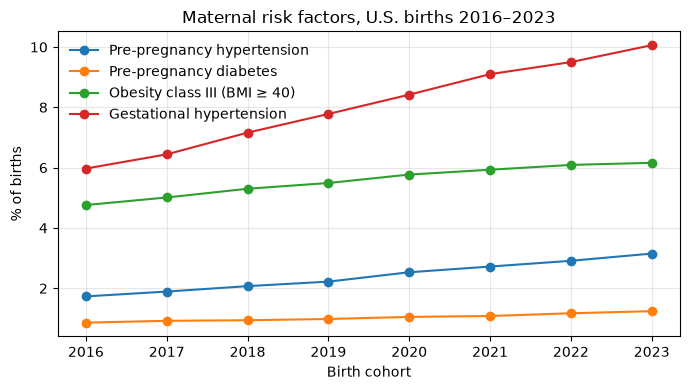

In [5]:
tc = pl.read_csv(REPORTS / "table1_by_cohort.csv", infer_schema_length=0)
years = [str(y) for y in range(2016, 2024)]
series = {
    "Pre-pregnancy hypertension": ("Pre-pregnancy hypertension", "Yes"),
    "Pre-pregnancy diabetes": ("Pre-pregnancy diabetes", "Yes"),
    "Obesity class III (BMI ≥ 40)": ("Pre-pregnancy BMI", "Obesity III >=40"),
    "Gestational hypertension": ("Gestational hypertension", "Yes"),
}
fig, ax = plt.subplots(figsize=(7, 4))
for label, (var, cat) in series.items():
    row = tc.filter((pl.col("variable") == var) & (pl.col("category") == cat))
    ax.plot([int(y) for y in years], [float(row[y][0]) for y in years], marker="o", label=label)
ax.set_xlabel("Birth cohort"); ax.set_ylabel("% of births"); ax.set_title("Maternal risk factors, U.S. births 2016–2023")
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "risk_factor_trends.png", dpi=150); plt.show()

**Reading.** All four factors rise. Pre-pregnancy hypertension almost doubles (1.7% to 3.2%). This matters for Part 1: models trained on 2016–2020 are tested on 2022–2023, when the population is different.

## 3. Prediction (Part 1)

**Question.** How well can information known before delivery predict death before age one in later cohorts (train 2016–2020, test 2022–2023)? Which items carry most of the predictive value?

**Main metric.** PR-AUC (area under the precision–recall curve), because only about 0.55% of babies die.

In [6]:
f = REPORTS / "part1_model_comparison.csv"
NAMES = {"a_baseline_rate": "(a) baseline rate", "b_age_race_logistic": "(b) age + race",
         "c_logistic": "(c) penalized logistic", "d_hgb": "(d) gradient boosting"}
if show_if(f):
    display(pl.read_csv(f).filter(pl.col("set") != "B_no_marital").with_columns(pl.col("model").replace(NAMES))
            .select("model", "set", "pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc", "cal_slope", "observed_over_expected"))
    display(pl.read_csv(REPORTS / "part1_strict.csv").filter(pl.col("model").str.contains("strict"))
            .select("model", "pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc", "cal_slope"))

model,set,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,cal_slope,observed_over_expected
str,str,f64,f64,f64,f64,f64,f64
"""(a) baseline rate""","""-""",0.005508,0.005453,0.005561,0.5,null,null
"""(b) age + race""","""-""",0.008723,0.00858,0.008874,0.610694,1.053528,0.995148
"""(c) penalized logistic""","""A""",0.018084,0.017505,0.018705,0.699831,0.964127,1.080541
"""(d) gradient boosting""","""A""",0.029366,0.028053,0.030828,0.710655,0.943835,1.038786
"""(c) penalized logistic""","""B""",0.023893,0.023059,0.024861,0.716641,0.948116,1.098589
"""(d) gradient boosting""","""B""",0.038034,0.036417,0.039641,0.739212,0.941963,1.029507


model,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,cal_slope
str,f64,f64,f64,f64,f64
"""d_hgb|A_strict""",0.019074,0.018361,0.019864,0.700773,0.936566
"""d_hgb|B_strict""",0.030004,0.028754,0.031425,0.721912,0.936827
"""difference A - A_strict""",0.010298,0.009189,0.011449,null,null
"""difference B - B_strict""",0.008012,0.007192,0.008868,null,null


**Reading.**
- The best model, gradient boosting with Set B, reaches **PR-AUC 0.038 (95% CI 0.036–0.040)** and **ROC-AUC 0.74** on 2022–2023 births. That is about 7 times the base rate (0.0055) and 4 times the age + race model (0.009). Pre-set checks 1 (beats model b) and 2 (calibration slope 0.94, rule 0.9–1.1) pass.
- **Timing leakage found.** Month prenatal care began and the two birth intervals depend on pregnancy length. Without them ("strict"), PR-AUC is **0.030 (0.029–0.031)** for Set B and 0.019 for Set A. Also without gestational diabetes, gestational hypertension and WIC ("strict-2", audit #4), Set B reaches **0.0275 (0.026–0.029)**. The strict numbers are the more honest estimate of what is known before delivery. A wider tuning grid (audit #5) changes PR-AUC by only +0.0002. This was a post-hoc analysis and is recorded in the plan's change log.
- **Most predictive items:** plurality (twins), then birth history. Pre-pregnancy hypertension and diabetes add little to *ranking* all births, because they are rare. Part 2 asks how much they raise the risk.
- **Fairness:** risk is under-predicted for NH American Indian/Alaska Native births (observed/expected 1.15).

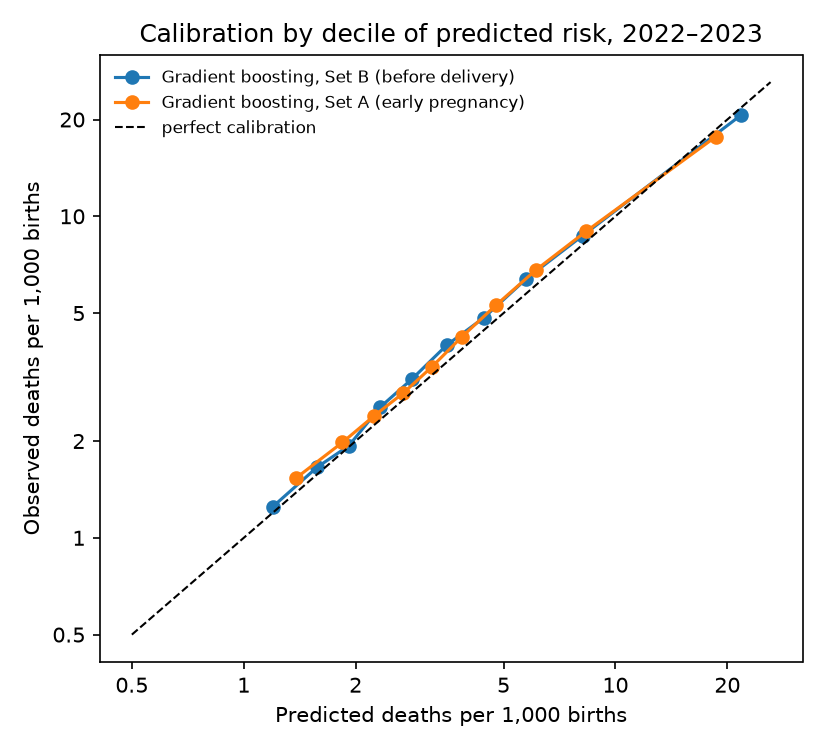

In [7]:
from IPython.display import Image
Image(filename=str(FIG / "part1_calibration.png"), width=480)

**Calibration.** Predicted and observed death rates agree across the ten risk groups. The top 10% of predicted risk holds 37% of all test deaths.

**Early vs late deaths.** Separate models predict neonatal deaths much better (PR-AUC 0.043, 12 times guessing) than postneonatal deaths (0.0067, 3.4 times). Twins and earlier birth outcomes drive early deaths; social and demographic items gain weight for late deaths (`03_prediction`, section 9).

## 4. Association (Part 2)

**Question.** After adjustment for confounders, how much do pre-pregnancy hypertension, pre-pregnancy diabetes, BMI class, smoking before pregnancy and the interval since the last pregnancy change the risk of infant death? Results are *risk ratios* (RR: the risk with the factor divided by the risk without it) and *risk differences* per 1,000 births.

In [8]:
f = REPORTS / "part2_results.csv"
if show_if(f):
    display(pl.read_csv(f).filter(pl.col("outcome") == "infant").select(
        "exposure", "label", "rr", "rr_lo", "rr_hi", "rd_per_1000", "evalue", "same_direction", "main_model"))

exposure,label,rr,rr_lo,rr_hi,rd_per_1000,evalue,same_direction,main_model
str,str,f64,f64,f64,f64,f64,i64,str
"""hypertension""","""yes""",1.495063,1.454724,1.536521,2.908215,2.355383,8,"""fixed"""
"""diabetes""","""yes""",1.841121,1.739796,1.948347,4.672241,3.085551,8,"""random"""
"""bmi""","""<18.5""",1.136545,1.101629,1.172568,0.622666,1.530486,8,"""fixed"""
"""bmi""","""25-29.9""",1.076945,1.061403,1.092715,0.313362,1.364809,8,"""fixed"""
"""bmi""","""30-34.9""",1.220195,1.20042,1.240296,0.961986,1.73854,8,"""fixed"""
"""bmi""","""35-39.9""",1.356245,1.31059,1.403491,1.615045,2.05134,8,"""random"""
"""bmi""",""">=40""",1.530916,1.498838,1.563682,2.547493,2.432464,8,"""fixed"""
"""smoking""","""any""",1.681455,1.620523,1.744678,3.622456,2.751893,8,"""random"""
"""interval""","""<6 mo""",1.217296,1.180625,1.255106,1.073588,1.731605,8,"""fixed"""


**Reading.** Complete-case results; multiple imputation of BMI, education and the interval changes no RR by more than 1.2%.
- All five factors raise the adjusted risk of infant death: diabetes **RR 1.84**, smoking before pregnancy **1.68**, BMI ≥40 **1.53**, hypertension **1.50**, interval <6 months **1.22** (vs 18–23 months).
- In absolute terms: about 4.7 (diabetes), 3.6 (smoking), 2.9 (hypertension) and 2.6 (BMI ≥40) extra deaths per 1,000 exposed births.
- BMI shows a dose–response (1.08 → 1.22 → 1.36 → 1.53). All 8 cohorts agree in direction.
- **Caveat:** the negative control (accident deaths) is also raised for smoking (1.81) and short intervals (1.54), but not for hypertension (1.03) or diabetes (0.80). The smoking and interval RRs probably include unmeasured social confounding. Smoking can cause house fires, but without fire, choking and poisoning deaths its accident RR is still 1.59 (audit #2).
- **Post-hoc, chapter 6:** the associations are cause-specific in the way biology predicts: diabetes acts most on birth defects (RR 2.59 vs 1.64 for other causes) and smoking on SUID (2.51 vs 1.40). A social confounder alone would raise all causes about equally.

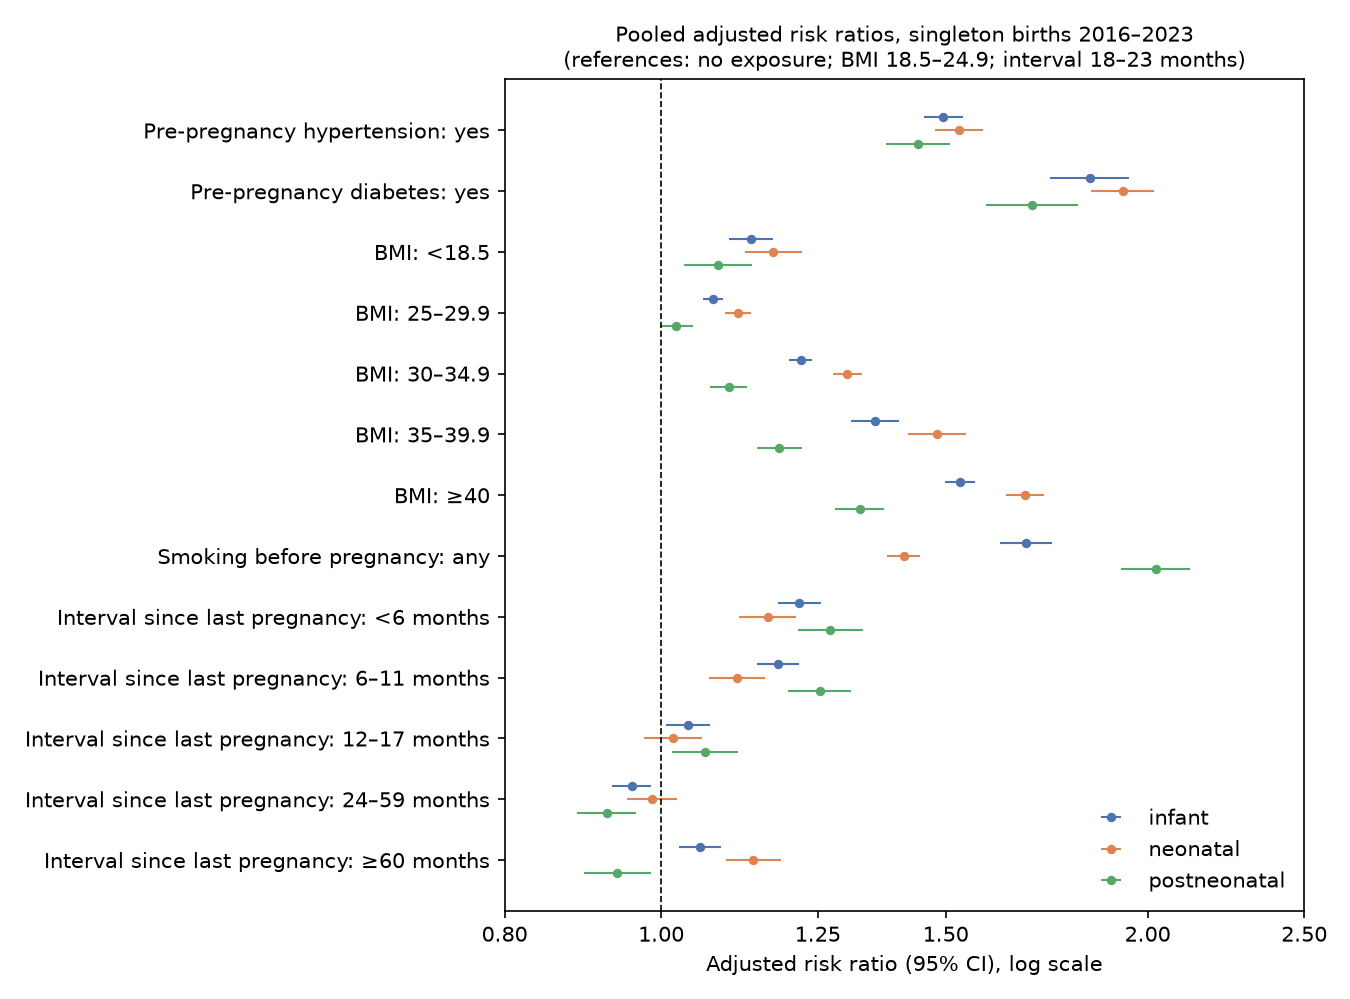

In [9]:
Image(filename=str(FIG / "part2_forest_pooled.png"), width=560)

## 5. Pre-set checks

**What.** Each claim has a test, fixed in the plan, that can fail it: the CDC benchmark, model calibration, leakage, direction in 7 of 8 cohorts, the negative-control outcome, and missing data.

In [10]:
f = REPORTS / "checks.csv"
if show_if(f):
    display(pl.read_csv(f).select("part", "check", "result", "status"))

part,check,result,status
str,str,str,str
"""Step 1""","""Record counts vs user guides""","""births 7/8, deaths 8/8""","""FAIL"""
"""Step 1""","""CDC Documentation Table 2 reproduced""","""exact in 6 cohorts (2018-2023); off in [2016,…","""FAIL"""
"""Part 1""","""1. Best model beats age + race model""","""0.0293 (0.0277 to 0.0308)""","""PASS"""
"""Part 1""","""2. Calibration slope""","""0.942 (0.933 to 0.950); O/E 1.03""","""PASS"""
"""Part 1""","""3. Single-input leakage""","""highest feduc 0.626""","""PASS"""
"""Part 1""","""Post-hoc: model without timing items""","""Set B PR-AUC 0.0300 (0.0288-0.0314) vs 0.0380""","""INFO"""
"""Part 2""","""Model code vs statsmodels""","""beta 1.3e-12, SE 4.7e-12, RD 4.3e-12""","""PASS"""
"""Part 2""","""DAG adjustment sets (back-door)""","""5/5 valid, 5/5 invalid with GA""","""PASS"""
"""Part 2""","""1. Direction in >= 7 of 8 cohorts (infant dea…","""13/13 exposure classes""","""PASS"""


**Reading.** 20 rows before the extra research: 18 checks fixed before the results and 2 post-hoc rows (INFO).
- **PASS (8):** Part 1 checks 1–3; the model code; the DAG sets; Part 2 direction in all 8 cohorts; the negative control for hypertension and diabetes (low power).
- **FAIL (2):** the 2020 guide prints a wrong birth count (a typo; the file and NCHS agree), and CDC Table 2 is not reproduced exactly for 2016 and 2017. The cause is CDC's own documents (a typo, a re-released 2016 file, a copy error in the 2017 guide), not our data.
- **WEAKENED (3):** the negative control (accident deaths) is raised for smoking, short intervals and BMI 30–34.9, so these associations probably include unmeasured social confounding.
- **APPLIED (2):** random effects where cohorts disagree, and multiple imputation; neither changes a conclusion.
- **INFO (5):** the strict Part 1 model, secondary-outcome directions, the collider demonstration, the Holm adjustment and the extra social markers (sensitivity c).

## 6. Extra research (post-hoc)

**What.** Deeper checks of Parts 1 and 2 (`notebooks/06_extra_research.ipynb`), with rules fixed before each run: cause of death, recording errors, stillbirths, mediation through gestational age, decision curves, and an external check against NVSR 69(9).

In [11]:
for name in ("extra_cause_predictions", "extra_stillbirth", "extra_mediation"):
    f = REPORTS / f"{name}.csv"
    if show_if(f):
        cols = {"extra_cause_predictions": ["exposure", "cause", "ratio", "ratio_lo", "ratio_hi", "prediction"],
                "extra_stillbirth": ["exposure", "label", "rr_live", "rr_composite", "rr_fetal", "verdict"],
                "extra_mediation": ["exposure", "label", "te_rr", "nde_rr", "prop_mediated", "prop_mediated_lo", "prop_mediated_hi"]}[name]
        display(pl.read_csv(f).select(cols))

exposure,cause,ratio,ratio_lo,ratio_hi,prediction
str,str,f64,f64,f64,str
"""hypertension""","""preterm / low birth weight""",0.950385,0.879277,1.027244,"""FAILS"""
"""diabetes""","""congenital anomalies""",1.576782,1.452463,1.711741,"""HOLDS"""
"""smoking""","""SUID""",1.795273,1.7283,1.864841,"""HOLDS"""


exposure,label,rr_live,rr_composite,rr_fetal,verdict
str,str,f64,f64,f64,str
"""hypertension""","""yes""",1.500215,1.736594,2.010466,"""NOT BIASED"""
"""diabetes""","""yes""",1.844651,2.482567,3.234655,"""BIASED"""
"""bmi""","""<18.5""",1.140186,1.088337,1.018769,"""NOT BIASED"""
"""bmi""","""25-29.9""",1.073248,1.109226,1.152887,"""NOT BIASED"""
"""bmi""","""30-34.9""",1.216285,1.269196,1.333733,"""NOT BIASED"""
"""bmi""","""35-39.9""",1.351164,1.406426,1.474143,"""NOT BIASED"""
"""bmi""",""">=40""",1.5286,1.591142,1.671144,"""NOT BIASED"""
"""smoking""","""any""",1.723618,1.599457,1.464567,"""NOT BIASED"""


exposure,label,te_rr,nde_rr,prop_mediated,prop_mediated_lo,prop_mediated_hi
str,str,f64,f64,f64,f64,f64
"""hypertension""","""yes""",1.507116,0.983496,1.032545,0.967323,1.090059
"""diabetes""","""yes""",1.806219,1.263562,0.673088,0.6309,0.71916
"""bmi""","""<18.5""",1.124152,0.982244,1.143016,0.939592,1.507374
"""bmi""","""25-29.9""",1.098742,1.06446,0.347195,0.284567,0.411879
"""bmi""","""30-34.9""",1.260165,1.128909,0.50451,0.46888,0.536149
"""bmi""","""35-39.9""",1.416934,1.194703,0.533013,0.504779,0.556346
"""bmi""",""">=40""",1.601588,1.293118,0.512759,0.492168,0.539245
"""smoking""","""any""",1.675665,1.435208,0.355881,0.344647,0.367987
"""interval""","""<6 mo""",1.210732,1.128702,0.389261,0.342866,0.447511


**Reading.**
- **Cause of death:** diabetes acts most on birth defects (ratio 1.58) and smoking on SUID (1.80), as their biology predicts. The hypertension prediction (preterm code P07) fails, but most of its effect appears to run through earlier delivery (proportion mediated 1.03 with `COMBGEST`, 1.16 with the obstetric estimate). These proportions are upper bounds: the direct-effect RR of hypertension falls below 1 (0.92), the signature of unmeasured gestational-age–death confounding.
- **Stillbirths:** with fetal deaths included, the diabetes RR rises from 1.84 to 2.48 and hypertension from 1.50 to 1.74. The live-birth RRs under-state the harm.
- **Recording errors:** every RR stays above 1; with the usual (non-differential) errors the true RRs are higher.
- **Decision curves:** the Part 1 models give a net benefit over "contact everyone" and "contact no one" at every threshold from 0.25% to 5%.
- **External check:** our births by BMI class are identical to NVSR 69(9).

## Limitations (so far)

- **Live births only (main analysis).** A factor that causes stillbirth looks weaker among live births; chapter 6 shows this for diabetes (1.84 → 2.48 with fetal deaths).
- **No geography.** The public files have no state or county, so area factors (poverty, hospitals) cannot be added per birth.
- **Certificate quality.** Risk factors come from birth certificates and are under-reported; chapter 6 shows that the usual errors make the RRs too low, not too high.
- **Timing.** Some pregnancy items (for example gestational diabetes) are recorded only if the pregnancy lasts long enough for the test.